In [27]:
import os
import zipfile

# Define zip file and extraction path
zip_path = "/content/dataset.zip"
extract_path = "/content/dataset"
genres_dir_name = "genres_original"

# Step 1: Unzip if necessary
if not os.path.exists(extract_path):
    if os.path.exists(zip_path):
        print("📦 Unzipping dataset...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("/content")
        print("✅ Unzipping completed.")
    else:
        print("❌ Zip file not found:", zip_path)
else:
    print("✅ Dataset folder already extracted.")

# Step 2: Verify base dataset path
if os.path.exists(extract_path):
    print("✅ Found base path:", extract_path)
    contents = os.listdir(extract_path)
    print("📁 Contents of dataset:", contents)

    # Step 3: Check for genres_original folder
    genres_path = os.path.join(extract_path, genres_dir_name)
    if os.path.exists(genres_path):
        genres = sorted(os.listdir(genres_path))
        print("🎵 Available genres:", genres)
    else:
        print(f"❌ '{genres_dir_name}' folder not found inside dataset.")
else:
    print("❌ Dataset path does not exist:", extract_path)


📦 Unzipping dataset...
✅ Unzipping completed.
✅ Found base path: /content/dataset
📁 Contents of dataset: ['images_original', 'genres_original']
🎵 Available genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


In [28]:
import os

# Set the base path
base_path = "/content/dataset"

# Check if the base path exists
if os.path.exists(base_path):
    print("✅ Found base path:", base_path)
    # List contents of the dataset folder
    contents = os.listdir(base_path)
    print("📁 Contents of dataset:", contents)

    # Check for genres_original
    genres_path = os.path.join(base_path, "genres_original")
    if os.path.exists(genres_path):
        genres = os.listdir(genres_path)
        print("🎵 Available genres:", genres)
    else:
        print("❌ 'genres_original' folder not found in dataset.")
else:
    print("❌ The path '/content/Data/dataset' does not exist.")

✅ Found base path: /content/dataset
📁 Contents of dataset: ['images_original', 'genres_original']
🎵 Available genres: ['blues', 'rock', 'classical', 'metal', 'disco', 'jazz', 'country', 'pop', 'hiphop', 'reggae']


In [29]:
def audio_to_mel_spectrogram(audio_path, genre, filename):
    try:
        # Load the audio file
        y, sr = librosa.load(audio_path, sr=None)  # sr=None keeps original sampling rate

        # Generate Mel spectrogram
        mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
        mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)

        # Plot and save the spectrogram
        plt.figure(figsize=(10, 4))
        librosa.display.specshow(mel_spectrogram_db, x_axis='time', y_axis='mel', sr=sr)
        plt.colorbar(format='%+2.0f dB')
        plt.title(f"Mel Spectrogram - {filename}")
        mel_image_path = os.path.join(output_path, f"{genre}_{filename}.png")
        plt.savefig(mel_image_path, bbox_inches='tight')
        plt.close()
    except Exception as e:
        print(f"❌ Skipped {filename} due to error: {e}")


In [30]:
import soundfile as sf

def is_valid_audio(file_path):
    try:
        with sf.SoundFile(file_path) as f:
            return True
    except:
        return False


In [ ]:
if filename.endswith(".wav"):
    audio_path = os.path.join(genre_folder, filename)
    if is_valid_audio(audio_path):
        audio_to_mel_spectrogram(audio_path, genre, filename)
    else:
        print(f"⚠️ Invalid audio file skipped: {filename}")


NameError: name 'filename' is not defined

In [32]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf

# Paths
input_path = "/content/dataset/genres_original"  # Path to the original dataset
output_path = "/content/mel_spectrograms"  # Path to save Mel spectrograms

# Create output directory if it doesn't exist
os.makedirs(output_path, exist_ok=True)

# Optional: check for audio file validity
def is_valid_audio(file_path):
    try:
        with sf.SoundFile(file_path) as f:
            return True
    except:
        return False

# Convert a single audio file to Mel spectrogram
def audio_to_mel_spectrogram(audio_path, genre, filename):
    try:
        # Load audio file
        y, sr = librosa.load(audio_path, sr=None)  # Keep original sampling rate

        # Generate Mel spectrogram
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

        # Create genre subdirectory
        genre_output_dir = os.path.join(output_path, genre)
        os.makedirs(genre_output_dir, exist_ok=True)

        # Plot and save spectrogram
        plt.figure(figsize=(3, 3))
        librosa.display.specshow(mel_spec_db, x_axis=None, y_axis=None, sr=sr)
        plt.axis('off')  # No axes for image clarity
        save_path = os.path.join(genre_output_dir, filename.replace('.wav', '.png'))
        plt.savefig(save_path, bbox_inches='tight', pad_inches=0)
        plt.close()
    except Exception as e:
        print(f"❌ Skipped {filename} due to error: {e}")

# Loop through all genres and process files
genres = os.listdir(input_path)
for genre in genres:
    genre_folder = os.path.join(input_path, genre)

    if os.path.isdir(genre_folder):  # Process only if it's a directory
        print(f"Processing genre: {genre}")

        # Loop through all files in the genre folder
        for filename in os.listdir(genre_folder):
            if filename.endswith(".wav"):
                file_path = os.path.join(genre_folder, filename)

                # Check if the audio file is valid
                if is_valid_audio(file_path):
                    audio_to_mel_spectrogram(file_path, genre, filename)
                else:
                    print(f"⚠️ Invalid audio file skipped: {filename}")


Processing genre: blues
Processing genre: rock
Processing genre: classical
Processing genre: metal
Processing genre: disco
Processing genre: jazz
⚠️ Invalid audio file skipped: jazz.00054.wav
Processing genre: country
Processing genre: pop
Processing genre: hiphop
Processing genre: reggae


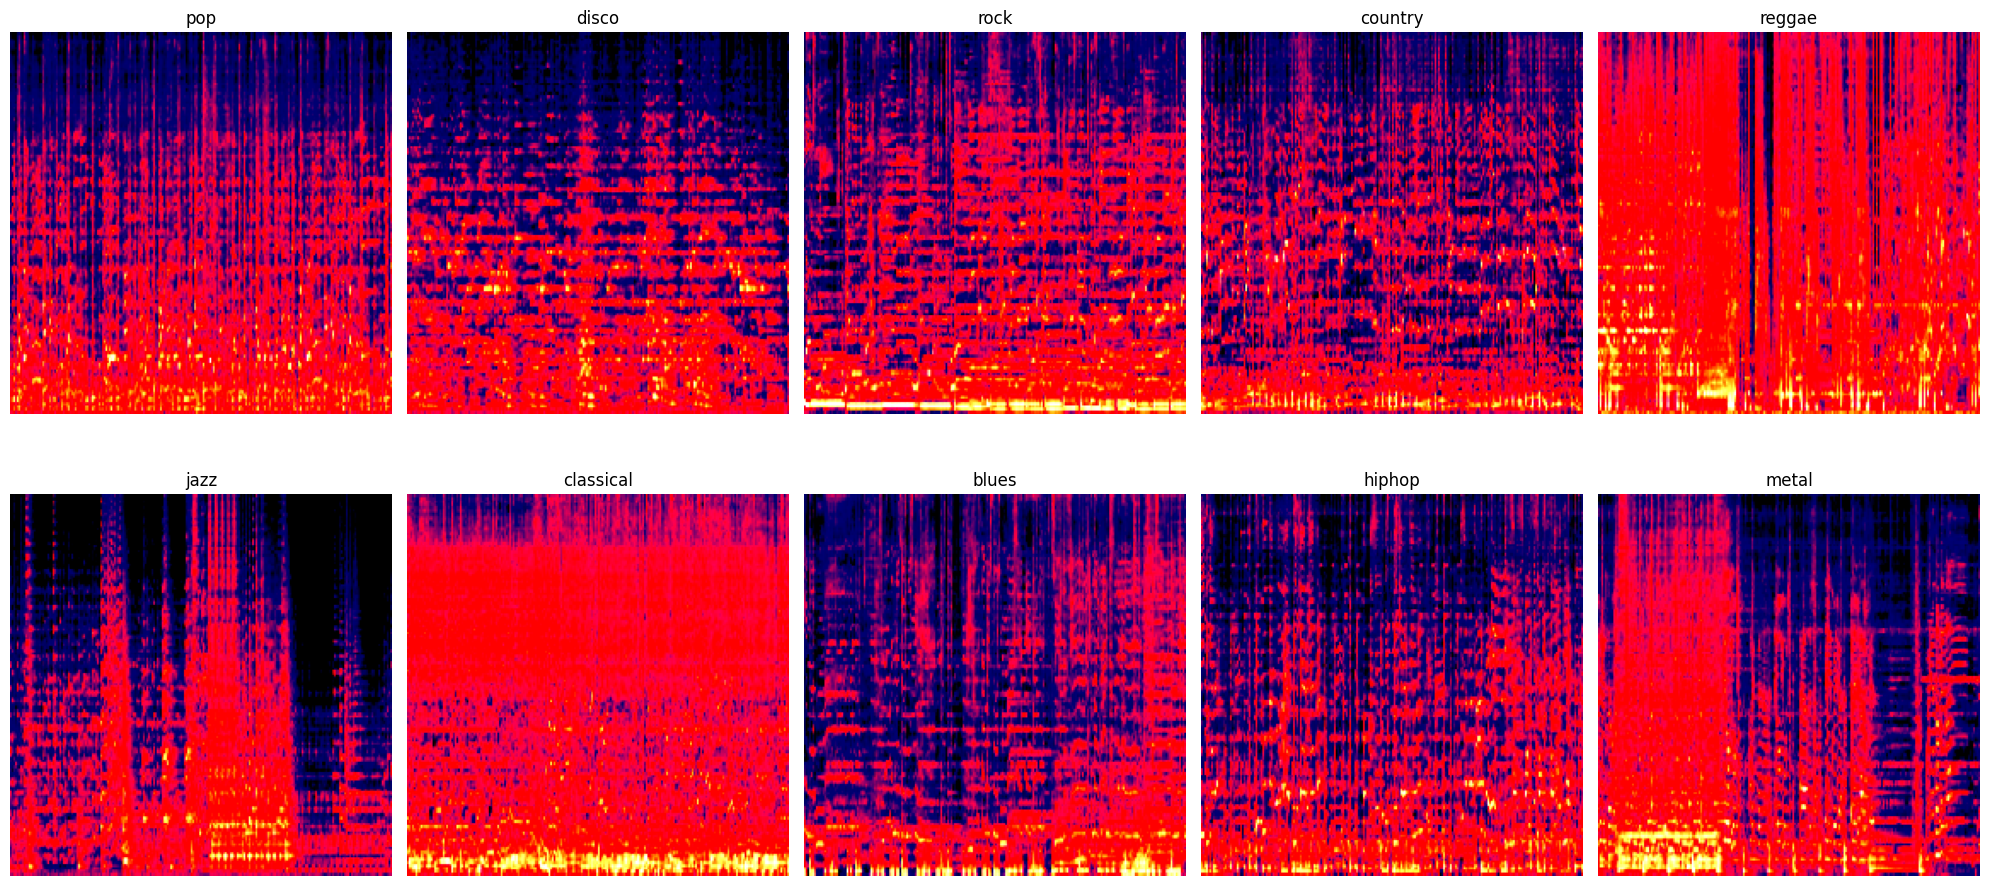

In [49]:
import matplotlib.pyplot as plt
import torch

# Define genre labels (classes)
class_names = ['pop', 'disco', 'rock', 'country', 'reggae', 'jazz', 'classical', 'blues', 'hiphop', 'metal']

# Dictionary to store one image per class
examples_per_class = {}

# Loop through the dataset and collect one example per class
for img, label in train_dataset:
    genre = class_names[label]
    if genre not in examples_per_class:
        examples_per_class[genre] = img
    if len(examples_per_class) == len(class_names):
        break  # stop once we have one example for each class

# Plot
plt.figure(figsize=(20, 10))
for idx, (genre, img) in enumerate(examples_per_class.items()):
    plt.subplot(2, 5, idx + 1)
    img_np = img.permute(1, 2, 0).numpy()  # Convert from [C,H,W] to [H,W,C]
    plt.imshow(img_np)
    plt.title(genre)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [33]:
import os

# Base directory where mel spectrograms are saved
base_dir = "/content/mel_spectrograms"

# Loop through each genre directory
for genre in os.listdir(base_dir):
    genre_dir = os.path.join(base_dir, genre)

    # Check if it's a directory (genre)
    if os.path.isdir(genre_dir):
        # Loop through each spectrogram file in the genre folder
        for filename in os.listdir(genre_dir):
            if filename.endswith(".png") and filename.startswith(genre + "_"):
                # Remove redundant genre prefix
                new_name = filename.replace(genre + "_", "", 1)
                os.rename(
                    os.path.join(genre_dir, filename),
                    os.path.join(genre_dir, new_name)
                )
                print(f"Renamed: {filename} -> {new_name}")


In [34]:
# Clean up filenames by removing the genre prefix (e.g., country_country.00000.wav.png -> 00000.wav.png)
import os

base_dir = "/content/mel_spectrograms"

for genre in os.listdir(base_dir):
    genre_path = os.path.join(base_dir, genre)
    if os.path.isdir(genre_path):
        for filename in os.listdir(genre_path):
            if filename.endswith(".png") and filename.startswith(genre + "_"):
                # Remove redundant genre prefix
                new_name = filename.replace(genre + "_", "", 1)
                os.rename(
                    os.path.join(genre_path, filename),
                    os.path.join(genre_path, new_name)
                )


In [35]:
import os
import shutil
import random
from sklearn.model_selection import train_test_split

# Paths
input_path = "/content/mel_spectrograms"  # Path to the generated Mel spectrograms
output_train_path = "/content/mel_spectrograms/train"
output_val_path = "/content/mel_spectrograms/val"
output_test_path = "/content/mel_spectrograms/test"

# Create output directories for train, validation, and test sets
os.makedirs(output_train_path, exist_ok=True)
os.makedirs(output_val_path, exist_ok=True)
os.makedirs(output_test_path, exist_ok=True)

# Function to split files into train, validation, and test sets
def split_data(genre_folder, genre):
    # List all Mel spectrograms in the genre folder
    mel_files = [f for f in os.listdir(genre_folder) if f.endswith('.png')]

    # If no files found, skip the genre folder
    if not mel_files:
        print(f"⚠️ No Mel spectrograms found in {genre_folder}. Skipping...")
        return

    # Split the files into training, validation, and test sets
    train_files, test_files = train_test_split(mel_files, test_size=0.2, random_state=42)  # 80% train, 20% test
    val_files, test_files = train_test_split(test_files, test_size=0.5, random_state=42)  # Split test set into 50% val and 50% test

    # Move files to their respective directories
    for file_set, output_dir in zip([train_files, val_files, test_files],
                                    [output_train_path, output_val_path, output_test_path]):
        genre_output_dir = os.path.join(output_dir, genre)
        os.makedirs(genre_output_dir, exist_ok=True)

        for file in file_set:
            src_path = os.path.join(genre_folder, file)
            dest_path = os.path.join(genre_output_dir, file)
            shutil.move(src_path, dest_path)
            print(f"Moved {file} to {output_dir}/{genre}")

# Process each genre folder
genres = os.listdir(input_path)
for genre in genres:
    genre_folder = os.path.join(input_path, genre)
    if os.path.isdir(genre_folder):  # Process only directories
        print(f"Processing genre: {genre}")
        split_data(genre_folder, genre)

print("Dataset split into train, validation, and test sets successfully.")


Processing genre: blues
Moved blues.00045.png to /content/mel_spectrograms/train/blues
Moved blues.00038.png to /content/mel_spectrograms/train/blues
Moved blues.00003.png to /content/mel_spectrograms/train/blues
Moved blues.00012.png to /content/mel_spectrograms/train/blues
Moved blues.00052.png to /content/mel_spectrograms/train/blues
Moved blues.00061.png to /content/mel_spectrograms/train/blues
Moved blues.00046.png to /content/mel_spectrograms/train/blues
Moved blues.00068.png to /content/mel_spectrograms/train/blues
Moved blues.00085.png to /content/mel_spectrograms/train/blues
Moved blues.00083.png to /content/mel_spectrograms/train/blues
Moved blues.00072.png to /content/mel_spectrograms/train/blues
Moved blues.00094.png to /content/mel_spectrograms/train/blues
Moved blues.00019.png to /content/mel_spectrograms/train/blues
Moved blues.00086.png to /content/mel_spectrograms/train/blues
Moved blues.00093.png to /content/mel_spectrograms/train/blues
Moved blues.00063.png to /conte

In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
import os
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import numpy as np


In [37]:
# Define the data directories
train_dir = '/content/mel_spectrograms/train'
val_dir = '/content/mel_spectrograms/val'
test_dir = '/content/mel_spectrograms/test'

# Define image transformations (normalization)
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224 (suitable for pre-trained models)
    transforms.ToTensor(),          # Convert images to PyTorch tensors
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet stats for transfer learning
])

# Load the datasets
train_dataset = ImageFolder(root=train_dir, transform=transform)
val_dataset = ImageFolder(root=val_dir, transform=transform)
test_dataset = ImageFolder(root=test_dir, transform=transform)

# DataLoader for batch processing
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [38]:
import torch.nn as nn

class MusicGenreCNN_Simplified(nn.Module):
    def __init__(self, num_classes):
        super(MusicGenreCNN_Simplified, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Linear(256, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x  # No softmax here if using CrossEntropyLoss


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_model(model, train_loader, val_loader, epochs, device, model_name="Model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = 100 * correct / total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion, device)

        print(f"{model_name} | Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f}, "
              f"Train Acc: {train_acc:.2f}%, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

def evaluate_model(model, loader, criterion, device):
    model.eval()
    loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = loss / len(loader)
    return avg_loss, accuracy


In [39]:
def test_model(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy for model: {100 * correct / total:.2f}%")


In [ ]:
import torch
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 5  # You can adjust the number of epochs as needed

# Model: Simplified Version
model_simplified = MusicGenreCNN_Simplified(num_classes=len(train_dataset.classes)).to(device)
print("\nTraining Model: Simplified CNN")
train_model(model_simplified, train_loader, val_loader, epochs, device, model_name="Simplified_CNN")
test_model(model_simplified, test_loader, device)

torch.cuda.empty_cache()  # Clean GPU memory



Training Model: Simplified CNN
Simplified_CNN | Epoch 1/5 | Train Loss: 2.2372, Train Acc: 15.89%, Val Loss: 2.0714, Val Acc: 20.00%
Simplified_CNN | Epoch 2/5 | Train Loss: 2.0953, Train Acc: 18.40%, Val Loss: 2.0840, Val Acc: 20.00%
Simplified_CNN | Epoch 3/5 | Train Loss: 2.0435, Train Acc: 18.65%, Val Loss: 2.0095, Val Acc: 24.00%
Simplified_CNN | Epoch 4/5 | Train Loss: 1.9902, Train Acc: 23.40%, Val Loss: 2.0264, Val Acc: 23.00%
Simplified_CNN | Epoch 5/5 | Train Loss: 1.9766, Train Acc: 26.78%, Val Loss: 1.9863, Val Acc: 26.00%
Test Accuracy for model: 30.00%


In [40]:
import torch.nn as nn

class MusicGenreCNN_Dropout_BN(nn.Module):
    def __init__(self, num_classes):
        super(MusicGenreCNN_Dropout_BN, self).__init__()

        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)

        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)

        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

        self.global_pool = nn.AdaptiveAvgPool2d(1)  # Output: (batch_size, 256, 1, 1)
        self.fc1 = nn.Linear(256, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)  # Flatten

        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x  # No softmax if using CrossEntropyLoss


In [ ]:
import torch
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 5  # You can adjust the number of epochs as needed

# Model: Simplified Version
model_dropout_bn = MusicGenreCNN_Dropout_BN(num_classes=len(train_dataset.classes)).to(device)

print("\nTraining Model: MusicGenreCNN_Dropout_BN")
train_model(model_dropout_bn, train_loader, val_loader, epochs, device, model_name="MusicGenreCNN_Dropout_BN")
test_model(model_dropout_bn, test_loader, device)

torch.cuda.empty_cache()  # Clean GPU memory



Training Model: MusicGenreCNN_Dropout_BN
MusicGenreCNN_Dropout_BN | Epoch 1/5 | Train Loss: 1.9752, Train Acc: 26.53%, Val Loss: 2.0251, Val Acc: 20.00%
MusicGenreCNN_Dropout_BN | Epoch 2/5 | Train Loss: 1.6797, Train Acc: 35.54%, Val Loss: 1.5500, Val Acc: 44.00%
MusicGenreCNN_Dropout_BN | Epoch 3/5 | Train Loss: 1.5641, Train Acc: 42.30%, Val Loss: 1.5034, Val Acc: 47.00%
MusicGenreCNN_Dropout_BN | Epoch 4/5 | Train Loss: 1.4783, Train Acc: 48.19%, Val Loss: 1.8379, Val Acc: 33.00%
MusicGenreCNN_Dropout_BN | Epoch 5/5 | Train Loss: 1.4285, Train Acc: 48.69%, Val Loss: 1.3654, Val Acc: 47.00%


In [ ]:
test_model(model_dropout_bn, test_loader, device)

Test Accuracy for model: 48.00%


In [41]:
pip install scikit-learn matplotlib seaborn


In [42]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def evaluate_and_plot(model, test_loader, device, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    print("\nClassification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    # Plot confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title("Confusion Matrix")
    plt.show()


**results of using adam**



Classification Report:

              precision    recall  f1-score   support

       blues     0.6667    0.4000    0.5000        10
   classical     0.3704    1.0000    0.5405        10
     country     0.0000    0.0000    0.0000        10
       disco     0.0000    0.0000    0.0000        10
      hiphop     0.5385    0.7000    0.6087        10
        jazz     1.0000    0.2000    0.3333        10
       metal     0.2727    0.9000    0.4186        10
         pop     0.0000    0.0000    0.0000        10
      reggae     1.0000    0.2000    0.3333        10
        rock     0.1667    0.2000    0.1818        10

    accuracy                         0.3600       100
   macro avg     0.4015    0.3600    0.2916       100
weighted avg     0.4015    0.3600    0.2916       100



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


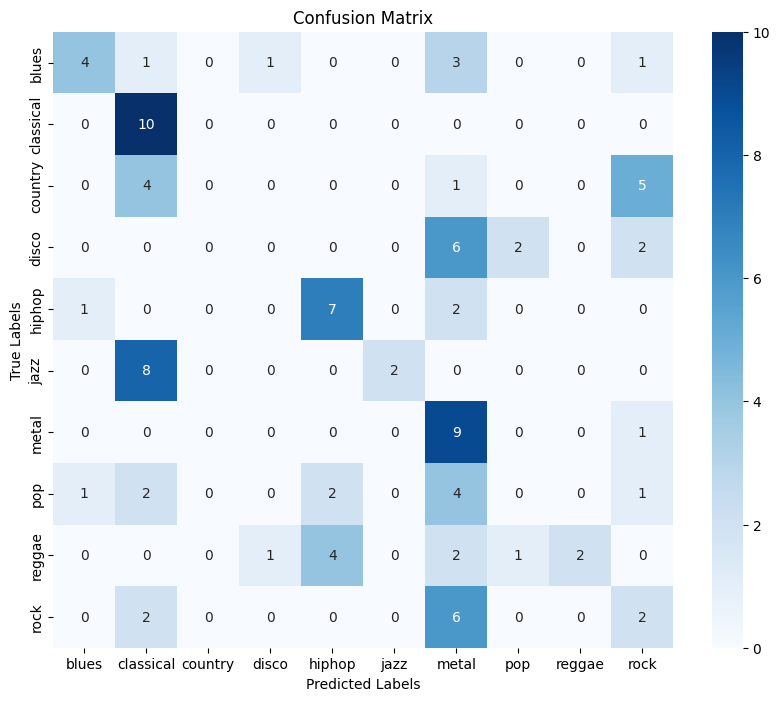


Classification Report:

              precision    recall  f1-score   support

       blues     0.0000    0.0000    0.0000        10
   classical     0.5833    0.7000    0.6364        10
     country     0.0000    0.0000    0.0000        10
       disco     0.0000    0.0000    0.0000        10
      hiphop     0.2857    0.6000    0.3871        10
        jazz     0.1429    0.2000    0.1667        10
       metal     0.5000    0.4000    0.4444        10
         pop     0.1000    0.1000    0.1000        10
      reggae     0.2188    0.7000    0.3333        10
        rock     0.0000    0.0000    0.0000        10

    accuracy                         0.2700       100
   macro avg     0.1831    0.2700    0.2068       100
weighted avg     0.1831    0.2700    0.2068       100



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


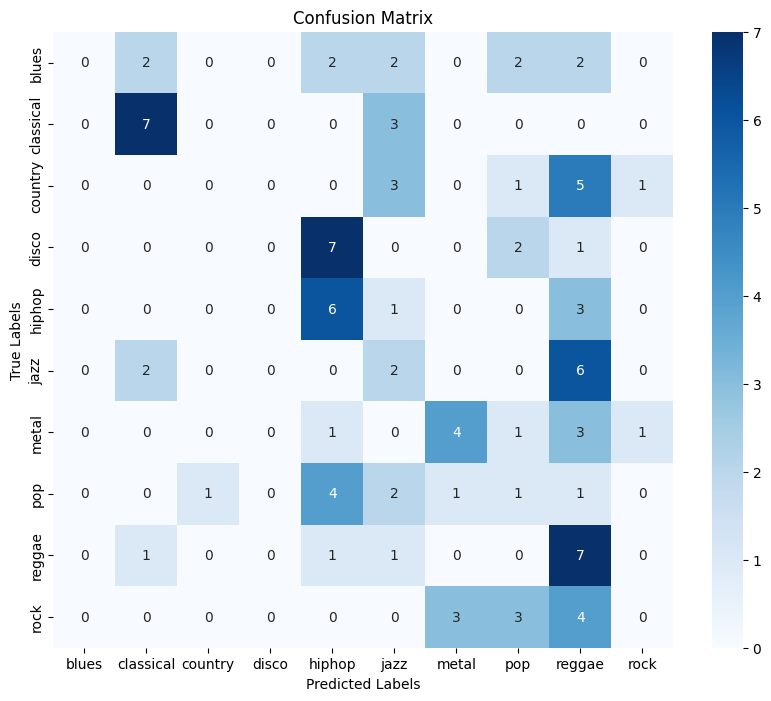

In [50]:
# Replace with actual class names from your dataset
class_names = train_dataset.classes

# For Dropout+BN model
evaluate_and_plot(model_dropout_bn, test_loader, device, class_names)

# For Simplified model
evaluate_and_plot(model_simplified, test_loader, device, class_names)


In [43]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_model(model, train_loader, val_loader, epochs, device, model_name="Model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.RMSprop(model.parameters(), lr=0.001)


    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = 100 * correct / total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion, device)

        print(f"{model_name} | Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f}, "
              f"Train Acc: {train_acc:.2f}%, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

def evaluate_model(model, loader, criterion, device):
    model.eval()
    loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = loss / len(loader)
    return avg_loss, accuracy


In [44]:
import torch
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 5  # You can adjust the number of epochs as needed

# Model: Simplified Version
model_simplified = MusicGenreCNN_Simplified(num_classes=len(train_dataset.classes)).to(device)
print("\nTraining Model: Simplified CNN")
train_model(model_simplified, train_loader, val_loader, epochs, device, model_name="Simplified_CNN")
test_model(model_simplified, test_loader, device)

torch.cuda.empty_cache()  # Clean GPU memory


Training Model: Simplified CNN
Simplified_CNN | Epoch 1/5 | Train Loss: 3.3460, Train Acc: 14.27%, Val Loss: 2.1562, Val Acc: 23.00%
Simplified_CNN | Epoch 2/5 | Train Loss: 2.1089, Train Acc: 19.27%, Val Loss: 2.1010, Val Acc: 19.00%
Simplified_CNN | Epoch 3/5 | Train Loss: 2.0438, Train Acc: 22.15%, Val Loss: 2.0233, Val Acc: 23.00%
Simplified_CNN | Epoch 4/5 | Train Loss: 2.0140, Train Acc: 24.16%, Val Loss: 2.0397, Val Acc: 29.00%
Simplified_CNN | Epoch 5/5 | Train Loss: 1.9814, Train Acc: 23.53%, Val Loss: 1.9499, Val Acc: 30.00%
Test Accuracy for model: 27.00%


In [45]:
import torch
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 5  # You can adjust the number of epochs as needed

# Model: Simplified Version
model_dropout_bn = MusicGenreCNN_Dropout_BN(num_classes=len(train_dataset.classes)).to(device)

print("\nTraining Model: MusicGenreCNN_Dropout_BN")
train_model(model_dropout_bn, train_loader, val_loader, epochs, device, model_name="MusicGenreCNN_Dropout_BN")
test_model(model_dropout_bn, test_loader, device)

torch.cuda.empty_cache()  # Clean GPU memory



Training Model: MusicGenreCNN_Dropout_BN
MusicGenreCNN_Dropout_BN | Epoch 1/5 | Train Loss: 2.2953, Train Acc: 19.02%, Val Loss: 2.1739, Val Acc: 16.00%
MusicGenreCNN_Dropout_BN | Epoch 2/5 | Train Loss: 1.7956, Train Acc: 32.54%, Val Loss: 1.5571, Val Acc: 41.00%
MusicGenreCNN_Dropout_BN | Epoch 3/5 | Train Loss: 1.6331, Train Acc: 39.05%, Val Loss: 1.7180, Val Acc: 46.00%
MusicGenreCNN_Dropout_BN | Epoch 4/5 | Train Loss: 1.4781, Train Acc: 46.18%, Val Loss: 1.5897, Val Acc: 45.00%
MusicGenreCNN_Dropout_BN | Epoch 5/5 | Train Loss: 1.4725, Train Acc: 43.18%, Val Loss: 1.7291, Val Acc: 43.00%
Test Accuracy for model: 36.00%



Classification Report:

              precision    recall  f1-score   support

       blues     0.6667    0.4000    0.5000        10
   classical     0.3704    1.0000    0.5405        10
     country     0.0000    0.0000    0.0000        10
       disco     0.0000    0.0000    0.0000        10
      hiphop     0.5385    0.7000    0.6087        10
        jazz     1.0000    0.2000    0.3333        10
       metal     0.2727    0.9000    0.4186        10
         pop     0.0000    0.0000    0.0000        10
      reggae     1.0000    0.2000    0.3333        10
        rock     0.1667    0.2000    0.1818        10

    accuracy                         0.3600       100
   macro avg     0.4015    0.3600    0.2916       100
weighted avg     0.4015    0.3600    0.2916       100



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


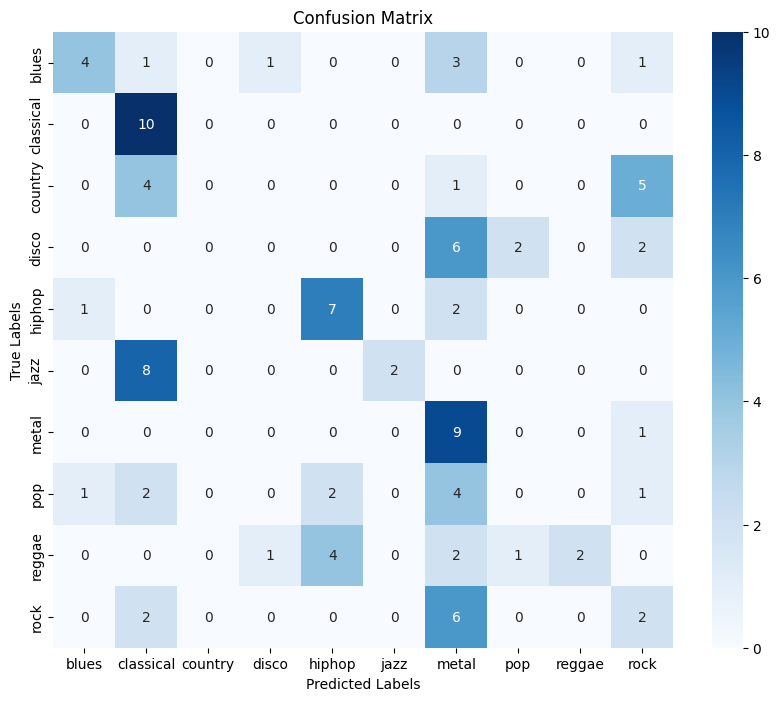


Classification Report:

              precision    recall  f1-score   support

       blues     0.0000    0.0000    0.0000        10
   classical     0.5833    0.7000    0.6364        10
     country     0.0000    0.0000    0.0000        10
       disco     0.0000    0.0000    0.0000        10
      hiphop     0.2857    0.6000    0.3871        10
        jazz     0.1429    0.2000    0.1667        10
       metal     0.5000    0.4000    0.4444        10
         pop     0.1000    0.1000    0.1000        10
      reggae     0.2188    0.7000    0.3333        10
        rock     0.0000    0.0000    0.0000        10

    accuracy                         0.2700       100
   macro avg     0.1831    0.2700    0.2068       100
weighted avg     0.1831    0.2700    0.2068       100



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


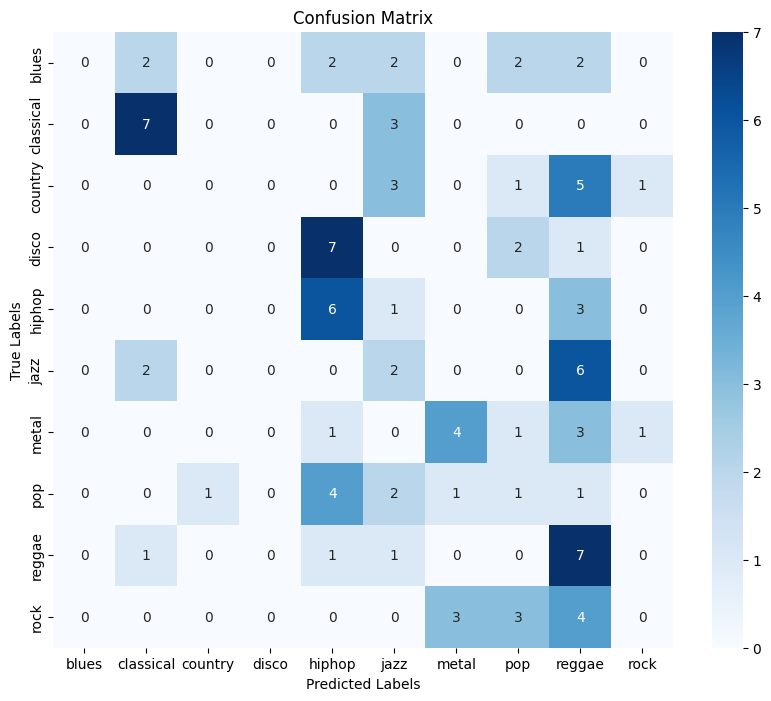

In [51]:
# Replace with actual class names from your dataset
class_names = train_dataset.classes

# For Dropout+BN model
evaluate_and_plot(model_dropout_bn, test_loader, device, class_names)

# For Simplified model
evaluate_and_plot(model_simplified, test_loader, device, class_names)


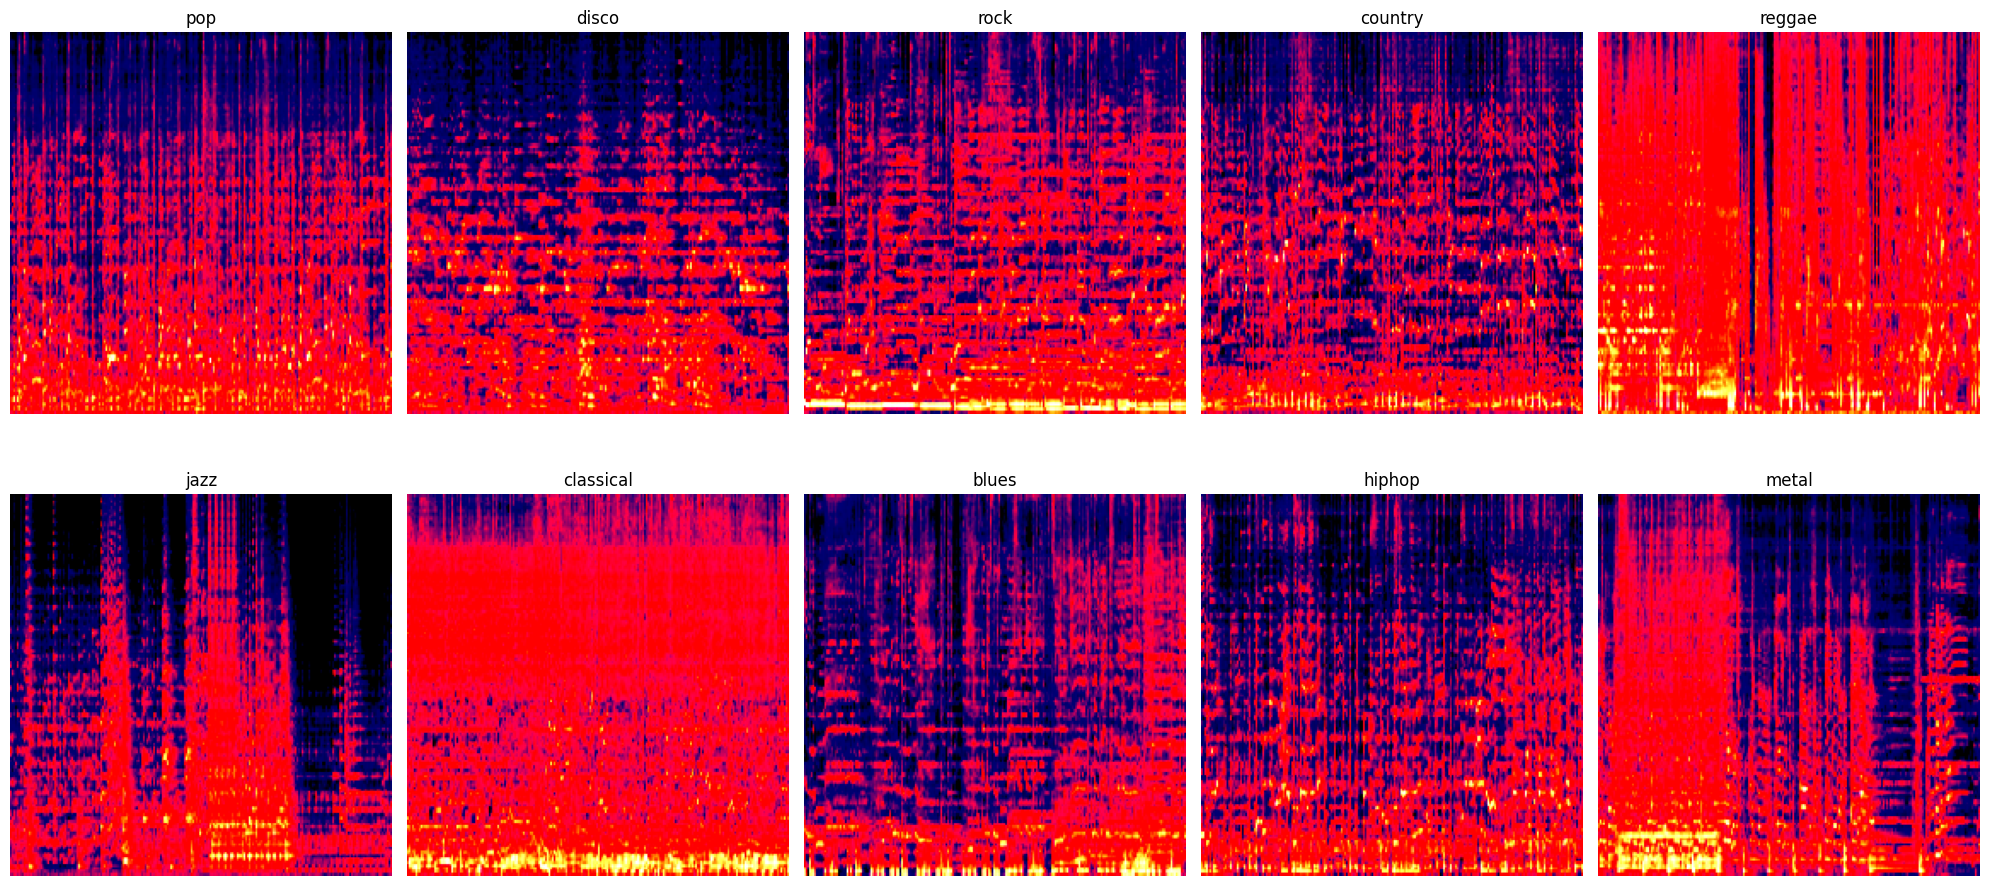

In [52]:
import matplotlib.pyplot as plt
import torch

# Define genre labels (classes)
class_names = ['pop', 'disco', 'rock', 'country', 'reggae', 'jazz', 'classical', 'blues', 'hiphop', 'metal']

# Dictionary to store one image per class
examples_per_class = {}

# Loop through the dataset and collect one example per class
for img, label in train_dataset:
    genre = class_names[label]
    if genre not in examples_per_class:
        examples_per_class[genre] = img
    if len(examples_per_class) == len(class_names):
        break  # stop once we have one example for each class

# Plot
plt.figure(figsize=(20, 10))
for idx, (genre, img) in enumerate(examples_per_class.items()):
    plt.subplot(2, 5, idx + 1)
    img_np = img.permute(1, 2, 0).numpy()  # Convert from [C,H,W] to [H,W,C]
    plt.imshow(img_np)
    plt.title(genre)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [54]:
plt.savefig("mel_spectrograms_per_genre.png", dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>

In [53]:
plt.tight_layout()
plt.suptitle("One Mel Spectrogram per Genre", fontsize=20, y=1.02)

# Save the plot
plt.savefig("mel_spectrograms_per_genre.png", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Define your class labels
class_names = ['pop', 'disco', 'rock', 'country', 'reggae', 'jazz', 'classical', 'blues', 'hiphop', 'metal']

# Dictionary to store one example per class
examples_per_class = {}

# Collect one example per genre from the dataset
for img, label in train_dataset:
    genre = class_names[label]
    if genre not in examples_per_class:
        examples_per_class[genre] = img
    if len(examples_per_class) == len(class_names):
        break  # Stop once we have one example for each class

# Plotting high-resolution images
plt.figure(figsize=(25, 10), dpi=100)  # Larger figure for high detail

for idx, genre in enumerate(class_names):
    img = examples_per_class[genre]

    # Convert tensor to numpy image format
    img_np = img.permute(1, 2, 0).numpy()  # [C, H, W] -> [H, W, C]

    # If your images are in [0, 255], normalize to [0, 1] for imshow
    if img_np.max() > 1.0:
        img_np = img_np / 255.0

    plt.subplot(2, 5, idx + 1)
    plt.imshow(img_np)
    plt.title(genre, fontsize=14)
    plt.axis('off')

plt.tight_layout()
plt.suptitle("One Mel Spectrogram per Genre", fontsize=20, y=1.02)
plt.show()
